# Анализ и прогноз потребления домашних хозяйств по регионам РФ, 2000-2023
Данные Росстата: фактическое конечное потребление домашних хозяйств на душу населения, текущие рыночные цены (руб.). Ряды номинальные, поэтому рост отражает и инфляцию.

In [1]:
%pip install -q sktime
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import linregress
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import Holt
from statsmodels.tsa.arima.model import ARIMA
from sktime.forecasting.naive import NaiveForecaster

URL = "https://raw.githubusercontent.com/nezhablack/russia-regions-consumption-forecast/main/rsdocs_1491005410458_wide_appendix_2025.csv"

## Этап 1. Загрузка и подготовка данных

In [2]:
raw_data = pd.read_csv(URL, dtype=str)      # читаем как текст, чтобы пропуски не испортили типы
raw_data.columns = [c.strip() for c in raw_data.columns]
raw_data = raw_data.loc[:, ~raw_data.columns.str.startswith("Unnamed")]   # пустая колонка в конце файла
name_col = raw_data.columns[0]
year_cols = [c for c in raw_data.columns if c.isdigit()]
print(raw_data.shape)
raw_data.info()
display(raw_data.head(3))

(96, 28)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   region_name     96 non-null     object
 1   region_code     94 non-null     object
 2   indicator_name  96 non-null     object
 3   measure_unit    96 non-null     object
 4   2000            92 non-null     object
 5   2001            92 non-null     object
 6   2002            92 non-null     object
 7   2003            92 non-null     object
 8   2004            92 non-null     object
 9   2005            92 non-null     object
 10  2006            92 non-null     object
 11  2007            92 non-null     object
 12  2008            92 non-null     object
 13  2009            92 non-null     object
 14  2010            92 non-null     object
 15  2011            94 non-null     object
 16  2012            94 non-null     object
 17  2013            94 non-null     object
 18  201

,region_name,region_code,indicator_name,measure_unit,2000,2001,2002,2003,2004,2005,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Фактическое конечное потребление домашних хозя...,NaN,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"24964,9","33073,8","42325,5",50809,"63177,6","79943,6",...,"279922,2","296330,1","335157,9","352032,4","378631,5","396539,7","409455,2","482117,7","537330,3","605276,8"
1,Центральный федеральный округ,30,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"37398,9","48743,1","60043,2","71997,2","86784,2","106512,6",...,"357669,5","371888,6","428461,6","449367,4","483617,8","504322,7","522640,3","622652,4","670468,1","745978,7"
2,Белгородская область,14000000000,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"19420,9","22799,1","26386,5",31254,"39422,8","48000,4",...,"234785,7","252179,1",299984,"321377,9","343531,1",362467,386681,"432635,6",488454,514718


In [3]:
raw_data[name_col] = raw_data[name_col].str.strip()
long_data = raw_data.melt(id_vars=name_col, value_vars=year_cols, var_name="year", value_name="value")
long_data.columns = ["region", "year", "value"]
long_data["year"] = long_data["year"].astype(int)
# пустые ячейки и символ пропуска превращаются в NaN через errors="coerce"
long_data["value"] = pd.to_numeric(long_data["value"].str.replace(",", ".").str.replace(r"\s", "", regex=True), errors="coerce")

# РФ, федеральные округа и дубли "без автономных округов" исключаем: работаем только с субъектами
is_aggregate = long_data["region"].str.contains(r"Российск\w+ Федерац|федеральн\w+ округ|без автономн", regex=True)
print("Исключены агрегаты:", sorted(long_data.loc[is_aggregate, "region"].unique()))
region_data = long_data[~is_aggregate]

# территории с пропусками исключаем: начало ряда достраивать нельзя
missing_years = region_data.groupby("region")["value"].apply(lambda s: s.isna().sum())
print("Исключены из-за пропусков (число лет без данных):")
print(missing_years[missing_years > 0])
region_series = region_data.pivot(index="year", columns="region", values="value")[missing_years[missing_years == 0].index]
print(region_series.shape)

Исключены агрегаты: ['Архангельская область без автономного округа', 'Дальневосточный федеральный округ', 'Приволжский федеральный округ', 'Северо-Западный федеральный округ', 'Северо-Кавказский федеральный округ', 'Сибирский федеральный округ', 'Тюменская область без автономных округов', 'Уральский федеральный округ', 'Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего', 'Центральный федеральный округ', 'Южный федеральный округ']
Исключены из-за пропусков (число лет без данных):
region
Ненецкий автономный округ                    3
Республика Крым                             14
Ханты-Мансийский автономный округ – Югра     3
Чеченская Республика                         5
Ямало-Ненецкий автономный округ              3
г. Севастополь                              14
Name: value, dtype: int64
(24, 79)


In [10]:
annual_growth = region_series.pct_change().stack() * 100

print("Самый большой годовой рост")
display(annual_growth.nlargest(1).round(1))

print("Самое большое годовое падение")
display(annual_growth.nsmallest(1).round(1))

Самый большой годовой рост


,,0
year,region,
2004,Красноярский край,208.0


Самое большое годовое падение


,,0
year,region,
2005,Красноярский край,-53.3


В исходном CSV 96 строк и 29 столбцов, один из которых полностью пустой. После его удаления данные перевели в длинный формат: одна строка соответствует одному региону и году. Годовые значения преобразовали в числа: десятичные запятые заменили точками, а пустые ячейки и обозначения пропусков учли как отсутствующие значения.

Из анализа исключили 11 строк по типу территории: итог по России, восемь федеральных округов и две дополнительные строки областей без автономных округов. Еще шесть регионов исключили из-за неполной истории: Республика Крым и Севастополь (по 14 пропущенных лет), Чеченская Республика (5 лет), Ненецкий, Ханты-Мансийский и Ямало-Ненецкий автономные округа (по 3 года). Пропуски не восстанавливали.

В итоговой выборке осталось 79 регионов с полными рядами за 2000-2023 годы: по 24 наблюдения на регион.

Проверка годовых изменений показала, что и самый большой рост (+208% в 2004 году), и самое большое падение (-53,3% в 2005 году) наблюдались в Красноярском крае. По этим изменениям нельзя установить, ошибочна ли запись, поэтому исходные значения оставили без изменений.

## Этап 2. Кластеризация
Используем медианный уровень, медианный годовой рост, рост за весь период и долю лет со снижением. Медианы меньше зависят от необычных значений. Стандартизация нужна, чтобы рубли и доли не задавали разный масштаб расстояний.

Силуэт составляет около 0,36, 0,335 и 0,285 при двух, трех и четырех группах. Выбираем три: отдельно видны регионы с высоким уровнем и меньшим накопленным ростом, регионы с отдельными снижениями и регионы без снижений. Четвертая группа дает более слабый силуэт.

In [4]:
annual_growth = region_series.pct_change().iloc[1:]
features = pd.DataFrame({"median_level": region_series.median(),
                         "median_growth": annual_growth.median(),
                         "total_growth": region_series.iloc[-1] / region_series.iloc[0] - 1,
                         "decline_share": (annual_growth < 0).mean()})
scaled_features = StandardScaler().fit_transform(features)
for cluster_count in (2, 3, 4):
    model = KMeans(cluster_count, n_init=20, random_state=0).fit(scaled_features)
    print(cluster_count, round(silhouette_score(scaled_features, model.labels_), 3))
    display(features.groupby(model.labels_).mean().round(3))
    if cluster_count == 3:
        cluster_model = model
cluster_labels = cluster_model.labels_

2 0.36


,median_level,median_growth,total_growth,decline_share
0,221147.133,0.131,25.815,0.043
1,183847.921,0.137,27.923,0.000


3 0.335


,median_level,median_growth,total_growth,decline_share
0,179357.600,0.138,28.899,0.047
1,169218.516,0.139,28.308,0.000
2,289022.467,0.120,22.774,0.017


4 0.289


,median_level,median_growth,total_growth,decline_share
0,173369.285,0.155,31.730,0.000
1,294049.811,0.120,22.662,0.019
2,168596.694,0.130,26.481,0.000
3,179357.600,0.138,28.899,0.047


Наибольший силуэт получился для двух кластеров 0,36, для трех он немного ниже 0,335, а для четырех - 0,289. Выбрали три кластера, потому что этот вариант отдельно выделяет регионы с высоким типичным уровнем потребления и меньшим накопленным ростом, а среди регионов с более низким уровнем различает траектории с годовыми снижениями и без них. Для прогнозирования возьмем по одному представителю из каждой группы.

In [11]:
for cluster in range(3):
    members = features.index[cluster_labels == cluster]
    print(f"Кластер {cluster}: {len(members)} регионов, среднее {region_series[members].mean().mean():.0f} руб.")
    print(", ".join(members))

Кластер 0: 14 регионов, среднее 188777 руб.
Алтайский край, Воронежская область, Забайкальский край, Кемеровская область, Красноярский край, Курганская область, Омская область, Приморский край, Республика Дагестан, Республика Калмыкия, Ростовская область, Ставропольский край, Тамбовская область, Челябинская область
Кластер 1: 50 регионов, среднее 186501 руб.
Амурская область, Архангельская область, Астраханская область, Белгородская область, Брянская область, Владимирская область, Волгоградская область, Вологодская область, Еврейская автономная область, Ивановская область, Иркутская область, Кабардино-Балкарская Республика, Калинингpадская область, Калужская область, Карачаево-Черкесская Республика, Кировская область, Костромская область, Краснодарский край, Курская область, Ленинградская область, Липецкая область, Московская область, Нижегородская область, Новгородская область, Новосибирская область, Оренбургская область, Орловская область, Пензенская область, Псковская область, Респу

## Этап 3. Отбор представителей
Берем ближайший к центру регион каждой группы: его профиль ближе к типичному профилю кластера.

In [6]:
distances = cluster_model.transform(scaled_features)
selected_regions = [features.index[np.argmin(np.where(cluster_labels == c, distances[:, c], np.inf))]
                    for c in range(3)]
rows = []
for cluster, region in enumerate(selected_regions):
    series = region_series[region]
    rows.append([region, cluster, series.mean(), series.min(), series.max(), linregress(series.index, series).slope])
display(pd.DataFrame(rows, columns=["Регион", "Кластер", "Среднее", "Минимум", "Максимум", "Наклон, руб./год"]).round(1))

,Регион,Кластер,Среднее,Минимум,Максимум,"Наклон, руб./год"
0,Забайкальский край,0,180943.7,14063.4,434815.3,17264.4
1,Еврейская автономная область,1,187223.8,16178.3,479398.5,17863.6
2,Мурманская область,2,294447.2,31624.0,727648.4,28385.8


Для прогноза выбраны Забайкальский край, Еврейская автономная область и Мурманская область - по одному региону, ближайшему к центру своего кластера. Наиболее выраженный линейный тренд в абсолютном выражении наблюдается в Мурманской области: около 28400 руб. на человека в год против 17300 в Забайкальском крае и 17900 в Еврейской автономной области. Это наклон в текущих ценах, а не оценка роста реального потребления.

## Этап 4. Анализ рядов
Трехлетнее скользящее среднее сглаживает отдельные скачки. Устойчивые многолетние циклы по 24 наблюдениям не устанавливаем, а внутригодовая сезонность на годовых данных не наблюдается. ADF проверяет единичный корень: при p >= 0,05 его не отвергаем. ACF и PACF строим на первых разностях, чтобы тренд уровня не определял весь график.

Забайкальский край ADF p (уровень) = 0.994 ADF p (разность) = 0.048 CV = 0.683 отклонение от тренда, % = 3.5


/tmp/ipykernel_1558/2392883488.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(r, "ADF p (уровень) =", round(adfuller(y, regression="ct", maxlag=2)[1], 3),
/tmp/ipykernel_1558/2392883488.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  "ADF p (разность) =", round(adfuller(y.diff().dropna(), maxlag=2)[1], 3),


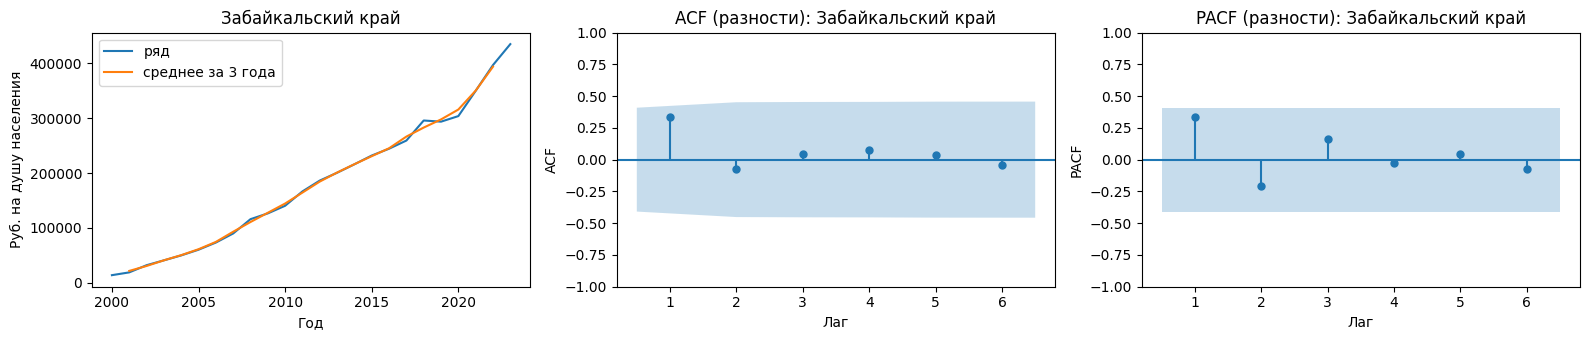

/tmp/ipykernel_1558/2392883488.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(r, "ADF p (уровень) =", round(adfuller(y, regression="ct", maxlag=2)[1], 3),
/tmp/ipykernel_1558/2392883488.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  "ADF p (разность) =", round(adfuller(y.diff().dropna(), maxlag=2)[1], 3),


Еврейская автономная область ADF p (уровень) = 1.0 ADF p (разность) = 0.973 CV = 0.687 отклонение от тренда, % = 1.76


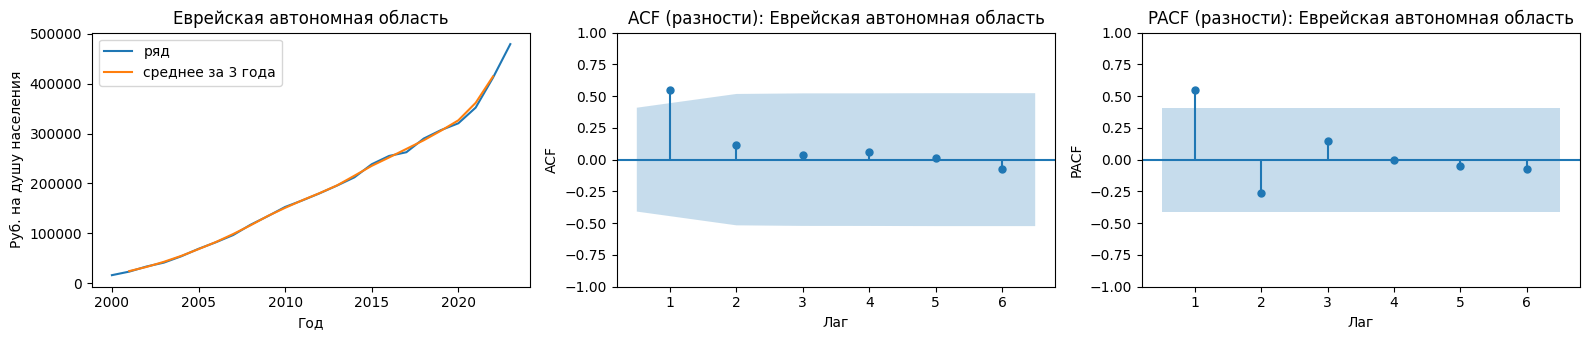

/tmp/ipykernel_1558/2392883488.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(r, "ADF p (уровень) =", round(adfuller(y, regression="ct", maxlag=2)[1], 3),
/tmp/ipykernel_1558/2392883488.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  "ADF p (разность) =", round(adfuller(y.diff().dropna(), maxlag=2)[1], 3),


Мурманская область ADF p (уровень) = 0.994 ADF p (разность) = 0.298 CV = 0.694 отклонение от тренда, % = 1.71


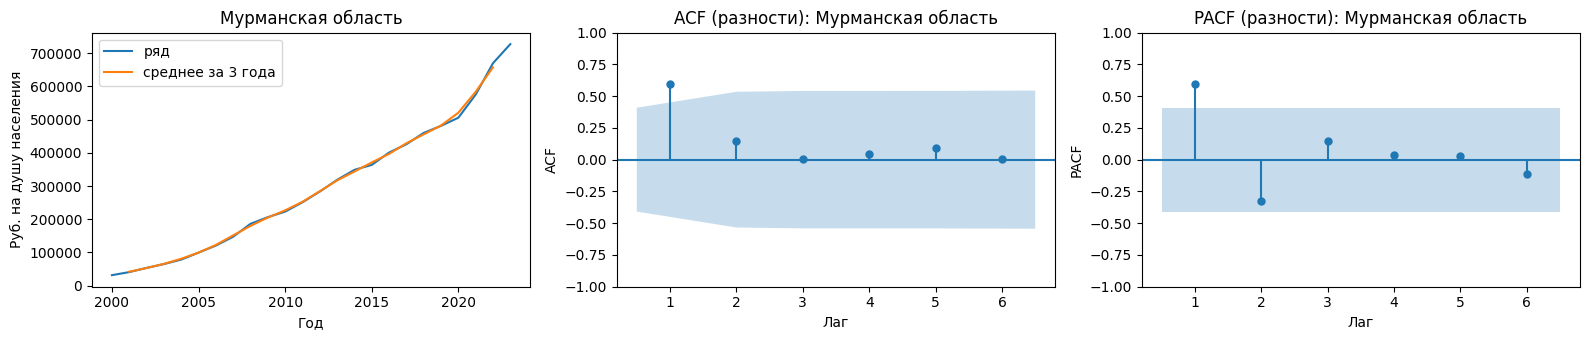

In [7]:
for r in selected_regions:
    y = region_series[r]
    trend = y.rolling(3, center=True).mean()
    cycle = y - trend
    print(r, "ADF p (уровень) =", round(adfuller(y, regression="ct", maxlag=2)[1], 3),
          "ADF p (разность) =", round(adfuller(y.diff().dropna(), maxlag=2)[1], 3),
          "CV =", round(y.std() / y.mean(), 3), "отклонение от тренда, % =", round((cycle / trend).std() * 100, 2))
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
    ax[0].plot(y, label="ряд"); ax[0].plot(trend, label="среднее за 3 года")
    ax[0].set_title(r); ax[0].set_xlabel("Год"); ax[0].set_ylabel("Руб. на душу населения"); ax[0].legend()
    dy = y.diff().dropna()
    plot_acf(dy, lags=6, zero=False, ax=ax[1], title="ACF (разности): " + r); ax[1].set_xlabel("Лаг"); ax[1].set_ylabel("ACF")
    plot_pacf(dy, method="ywm", lags=6, zero=False, ax=ax[2], title="PACF (разности): " + r); ax[2].set_xlabel("Лаг"); ax[2].set_ylabel("PACF")
    plt.tight_layout(); plt.show()


ADF на уровнях не отвергает единичный корень для всех трех регионов. На первых разностях только Забайкальский край погранично проходит порог (p = 0,048 против 0,973 в ЕАО и 0,298 в Мурманской области). У Мурманской области самый крутой тренд (28,4 тыс. руб. в год), у Забайкальского края самый большой относительный разброс вокруг тренда (3,50% против 1,71-1,76%). В Забайкалье первый лаг ACF и PACF не выделяется: начинаем с ARIMA(0,1,0). В ЕАО и Мурманской области выделяется первый лаг обоих графиков: проверяем, поможет ли p = 1 или q = 1.

## Этап 5. Прогнозирование
Обучение: 2000-2018 (19 из 24 наблюдений), тест: 2019-2023. Для ARIMA задаем одну разность и выбираем p и q по AIC на обучении. Сравниваем Holt, ARIMA и наивный прогноз по RMSE и MAPE. Победитель определяется по наименьшему RMSE.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Забайкальский край ARIMA: (0, 1, 0) лучшая модель: Holt


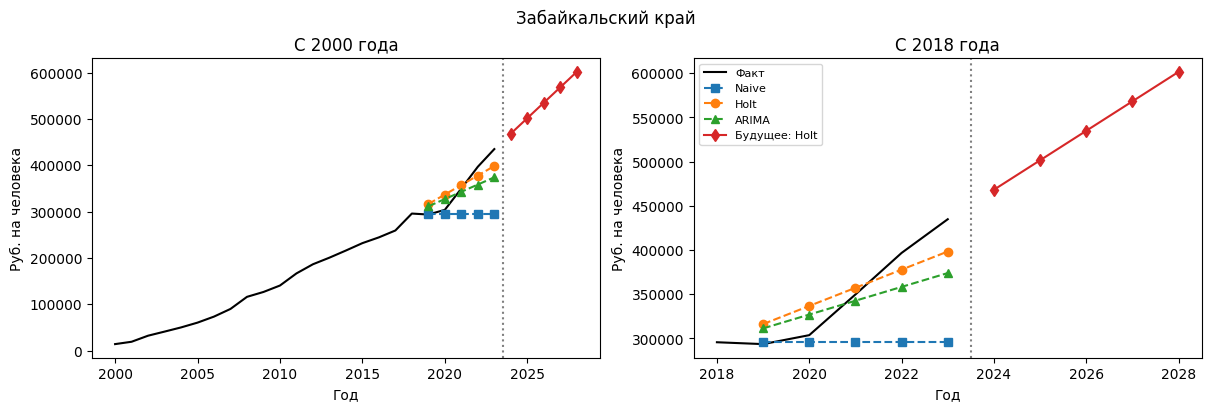

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Еврейская автономная область ARIMA: (0, 1, 0) лучшая модель: Holt


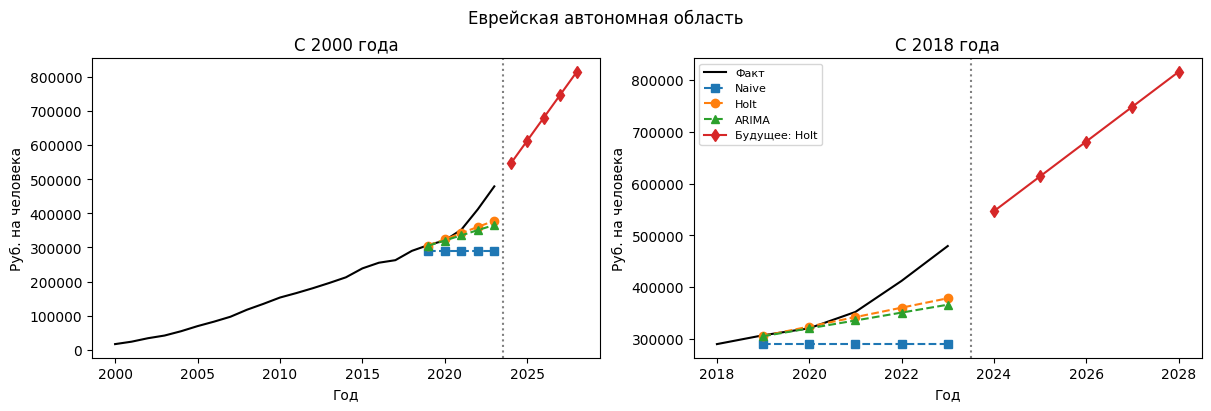

Мурманская область ARIMA: (0, 1, 0) лучшая модель: Holt


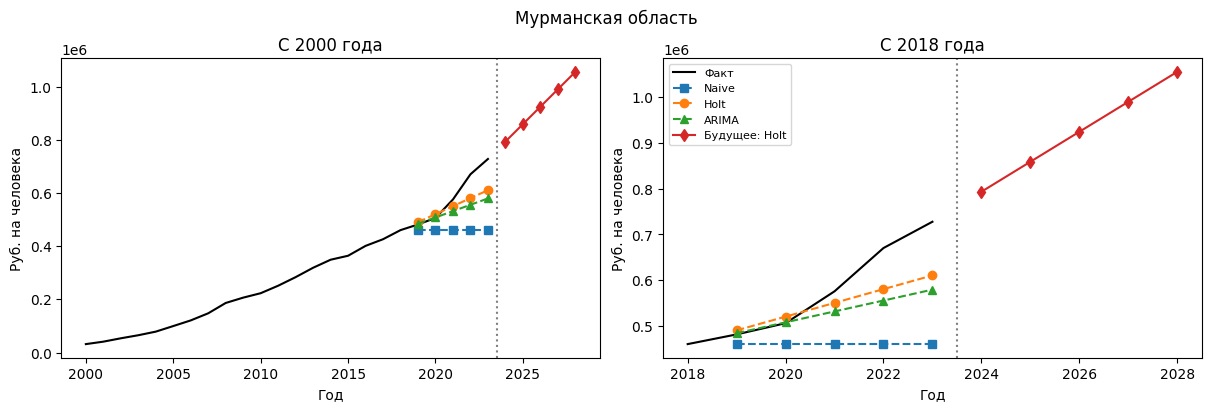

,Регион,Модель,"RMSE, руб.","MAPE, %"
0,Забайкальский край,Naive,80663.36,15.25
1,Забайкальский край,Holt,25880.41,6.78
2,Забайкальский край,ARIMA,34886.70,7.88
3,Еврейская автономная область,Naive,105705.23,20.38
4,Еврейская автономная область,Holt,50919.50,7.58
5,Еврейская автономная область,ARIMA,58084.55,8.77
6,Мурманская область,Naive,162157.32,20.32
7,Мурманская область,Holt,67458.47,7.72
8,Мурманская область,ARIMA,86172.24,9.21


,Регион,RMSE фикс.,"MAPE фикс., %",RMSE расшир.,"MAPE расшир., %"
0,Забайкальский край,25880.41,6.78,26195.75,6.70
1,Еврейская автономная область,50919.50,7.58,20962.44,3.55
2,Мурманская область,67458.47,7.72,38556.72,4.91


,Забайкальский край,Еврейская автономная область,Мурманская область
Год,,,
2024,468142.0,546668.0,793161.0
2025,501469.0,613938.0,858673.0
2026,534795.0,681207.0,924185.0
2027,568122.0,748477.0,989697.0
2028,601449.0,815747.0,1055209.0


In [8]:
def fit_arima(train):
    candidates = [ARIMA(train, order=order, trend="t").fit()
                  for order in [(0, 1, 0), (1, 1, 0), (0, 1, 1), (1, 1, 1)]]
    return min((model for model in candidates if model.mle_retvals["converged"]),
               key=lambda model: model.aic)


def forecast(model_name, train, steps):
    if model_name == "Naive":
        model = NaiveForecaster(strategy="last").fit(pd.Series(train))
        return model.predict(fh=list(range(1, steps + 1))).to_numpy()
    if model_name == "Holt":
        model = Holt(train / 1000, initialization_method="estimated").fit()
        return model.forecast(steps) * 1000
    return fit_arima(train).forecast(steps)


def metrics(actual, predicted):
    error = actual - predicted
    return np.sqrt(np.mean(error ** 2)), 100 * np.mean(np.abs(error / actual))


test_year_count = 5
forecast_year_count = 5
quality_rows = []
stability_rows = []
forecast_errors = {}
future_forecasts = {}
for region in selected_regions:
    series = region_series[region]
    values = series.to_numpy()
    train, test = values[:-test_year_count], values[-test_year_count:]
    arima = fit_arima(train)
    predictions = {name: forecast(name, train, test_year_count) for name in ["Naive", "Holt"]}
    predictions["ARIMA"] = arima.forecast(test_year_count)
    scores = {name: metrics(test, prediction) for name, prediction in predictions.items()}
    winner = min(scores, key=lambda name: scores[name][0])
    print(region, "ARIMA:", arima.model.order, "лучшая модель:", winner)
    quality_rows.extend([region, name, *scores[name]] for name in predictions)

    # В каждом окне есть только годы до прогнозируемого наблюдения.
    expanding = pd.Series({year: forecast(winner, values[:i], 1)[0]
                           for i, year in enumerate(series.index) if i >= 8})
    actual = series.loc[expanding.index]
    forecast_errors[region] = pd.DataFrame({"Факт": actual, "Прогноз": expanding, "Ошибка": actual - expanding})
    stability_rows.append([region, *scores[winner], *metrics(test, expanding.iloc[-test_year_count:].to_numpy())])
    future_years = range(series.index[-1] + 1, series.index[-1] + 1 + forecast_year_count)
    future = pd.Series(forecast(winner, values, forecast_year_count), index=future_years)
    future_forecasts[region] = future

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    fig.suptitle(region)
    for ax, start_year in zip(axes, [2000, 2018]):
        ax.plot(series.loc[start_year:], color="black", label="Факт")
        for (name, prediction), marker in zip(predictions.items(), ["s", "o", "^"]):
            ax.plot(series.index[-test_year_count:], prediction, "--", marker=marker, label=name)
        ax.plot(future, "d-", label="Будущее: " + winner)
        ax.axvline(2023.5, color="grey", linestyle=":")
        ax.set(title=f"С {start_year} года", xlabel="Год", ylabel="Руб. на человека")
    axes[1].legend(fontsize=8)
    plt.show()

display(pd.DataFrame(quality_rows, columns=["Регион", "Модель", "RMSE, руб.", "MAPE, %"]).round(2))
display(pd.DataFrame(stability_rows, columns=["Регион", "RMSE фикс.", "MAPE фикс., %",
                                              "RMSE расшир.", "MAPE расшир., %"]).round(2))
display(pd.DataFrame(future_forecasts).rename_axis("Год").round())

Holt выигрывает у всех трех представителей. Наивный прогноз не продолжает рост, поэтому отстает от факта. AIC выбрал ARIMA(0,1,0) с дрейфом: значимый первый лаг на полном ряду не гарантирует, что более сложная модель лучше на обучении. При ежегодном обновлении обе ошибки уменьшились у ЕАО и Мурманской области; у Забайкальского края MAPE немного снизилась, но RMSE выросла. Здесь сравниваются те же тестовые годы, но разные горизонты: один год против 1-5 лет.

## Этап 6. Ошибки
Выбираем пять крупнейших по модулю ошибок одношагового прогноза с 2008 года. Положительная ошибка означает, что модель занизила факт. Это ретроспективная диагностика, а не независимый тест.

In [12]:
for region, results in forecast_errors.items():
    print(region)
    top_years = results["Ошибка"].abs().nlargest(5).index
    display(results.loc[top_years].rename_axis("Год").round())

Забайкальский край


,Факт,Прогноз,Ошибка
Год,,,
2022,396702.0,355116.0,41586.0
2021,349729.0,319773.0,29957.0
2019,293610.0,316236.0,-22626.0
2018,295716.0,273630.0,22086.0
2009,126566.0,142091.0,-15525.0


Еврейская автономная область


,Факт,Прогноз,Ошибка
Год,,,
2022,412129.0,367909.0,44220.0
2021,352136.0,339263.0,12873.0
2018,290015.0,277175.0,12840.0
2015,238572.0,226362.0,12209.0
2017,262675.0,274751.0,-12076.0


Мурманская область


,Факт,Прогноз,Ошибка
Год,,,
2022,670185.0,606353.0,63832.0
2021,575586.0,532061.0,43524.0
2023,727648.0,764784.0,-37135.0
2009,206337.0,225109.0,-18772.0
2015,363833.0,380174.0,-16341.0


У всех трех регионов наибольшая абсолютная ошибка одношагового прогноза пришлась на 2022 год. Holt занизил прогноз на 41600 руб. на человека в Забайкальском крае, на 44200 руб. в ЕАО и на 63800 руб. в Мурманской области. В 2021 году модель также занизила прогноз во всех трех регионах. Потребление в эти годы росло быстрее, чем предполагала модель. По этим данным нельзя отдельно оценить вклад изменения цен и реального потребления.

- Забайкальский край: в 2019 году модель завысила прогноз на 22600 руб. Фактический показатель немного снизился по сравнению с 2018 годом, тогда как модель ожидала продолжения роста. В 2009 году прогноз также был выше факта. Возможно рост замедлился на фоне мирового кризиса.
- Еврейская автономная область: в 2015 году модель занизила прогноз на 12200 руб. Возможно, из-за изменения цен в 2014-2015 годах.
- Мурманская область: в 2023 году модель, наоборот, завысила прогноз на 37100 руб. После недооценки роста в 2022 году она могла продолжить слишком высокий темп, тогда как фактический прирост замедлился.

## Этап 7. Рекомендации

Забайкальский край

1. Для долгосрочного планирования взять 601000 руб. на человека в 2028 году как базовый ориентир в текущих ценах, а не как цель по росту реального потребления.
2. После выхода новых данных проверять, насколько прогноз отклонился от факта и в процентах, и в рублях. На тестовых годах у обновляемого одношагового прогноза процентная ошибка немного снизилась (с 6,78% до 6,7%), а ошибка в рублях выросла (с 25900 до 26200 руб. по RMSE). Поэтому по одной метрике нельзя сказать, что прогноз стал точнее.

Еврейская автономная область

1. Для планирования на ближайший год обновлять одношаговый прогноз после публикации каждого нового годового значения. В ретроспективной проверке его средняя абсолютная процентная ошибка составила 3,6%. Эту оценку не следует переносить на прогноз до 2028 года.
2. Использовать 816000 руб. на человека в 2028 году как номинальный ориентир. Если нужно оценить, насколько вырастет реальное потребление, сначала привести показатели 2023 и 2028 годов к сопоставимым ценам: разница около 336000 руб. в текущих ценах включает изменение цен.

Мурманская область

1. Если для сценарного планирования используется условный порог 1 млн руб. на человека, проверить два варианта: его достижение в 2027 году и в 2028 году. Базовый прогноз дает около 990000 руб. в 2027 и 1055000 руб. в 2028.
2. Не привязывать решение к точному году пересечения порога. В 2027 году прогноз ниже порога всего на 10000 руб., тогда как одношаговый RMSE на тесте составил около 39000 руб. Это сравнение показывает масштаб ошибки, но не определяет вероятность достижения порога.

## Этап 8. Выводы

По данным за 2000-2023 годы выделили три группы регионов. В первой типичный уровень потребления был выше, но относительный рост за весь период был меньше. Две другие группы имели более низкий уровень потребления и различались тем, были ли в их рядах годовые снижения.

На тестовом периоде 2019-2023 годов модель Holt показала наименьший RMSE у всех трех выбранных представителей: Забайкальского края, Еврейской автономной области и Мурманской области. Этот результат относится только к выбранным регионам и тестовым годам. Самые большие ошибки одношагового прогноза у всех трех регионов пришлись на 2022 год: фактическое потребление оказалось выше прогноза на 42-64 тыс. руб. на человека. Модель продолжала прошлый тренд и недооценила ускорение номинального роста.

### Ограничения

Для каждого региона было доступно 24 годовых наблюдения, из них только пять использовались для фиксированного теста. Регионы с неполными рядами не вошли в анализ, а качество прогнозов проверялось только для одного представителя каждого кластера. Показатель выражен в текущих ценах, поэтому прогноз не позволяет отделить изменение объема потребления от изменения цен. Модели также не учитывают внешние экономические факторы.

Для улучшения анализа можно пересчитать ряды в сопоставимых ценах, проверить модели на нескольких периодах с одинаковым горизонтом прогноза и включить в сравнение больше регионов из каждого кластера.